In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

# О датасете


In [ ]:
#!/bin/bash
curl -L -o titanic/titanic-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset
unzip titanic/titanic-dataset.zip

In [5]:
import os 
DATA_PATH=os.path.join("titanic", "Titanic-Dataset.csv")
data = pd.read_csv(DATA_PATH, sep=",")
print(data.shape)
print("Типы признаков:")
print(data.dtypes.to_string())

print("\nПропуски:", int(data.isna().sum().sum()))
print("Полных дубликатов строк:", int(data.duplicated().sum()))

constant_columns = [c for c in data.columns if data[c].nunique() == 1]
print("Константные признаки:", constant_columns)

print("\nОписательные статистики:")
data.head()

(891, 12)
Типы признаков:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Пропуски: 866
Полных дубликатов строк: 0
Константные признаки: []

Описательные статистики:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Мы видим, что у нас есть 11 признаков. Из них 6 числовых и 5 строковых. В данных есть пропуски. Дубликатов и константных признаков нет. Признаки `PassengerId` и `Name` можно исключить. Они приведут к бессмысленному запоминанию объекта. Строковые признаки нужно заменить на числовые через one-hot encoder.
# Изучение целевого признака

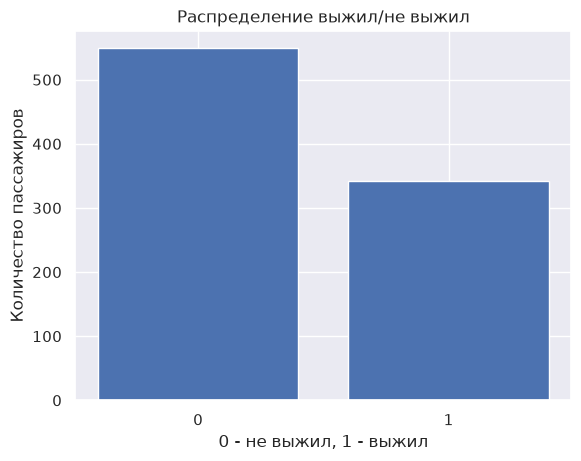

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [21]:
plt.figure()
counts = data['Survived'].value_counts().sort_index()
plt.bar(counts.index.astype(str), counts) 
plt.title('Распределение выжил/не выжил')
plt.xlabel("0 - не выжил, 1 - выжил")
plt.ylabel("Количество пассажиров")
plt.show()
print(data['Survived'].value_counts(normalize=True).mul(100).round(2))

Мы можем увидеть, что число невыживших больше, чем выживших. Выживших всего 38.38%. Значит accuracy не будет хорошей метрикой.
# Распределение признаков
Посмотрим на распределение числовых признаков.

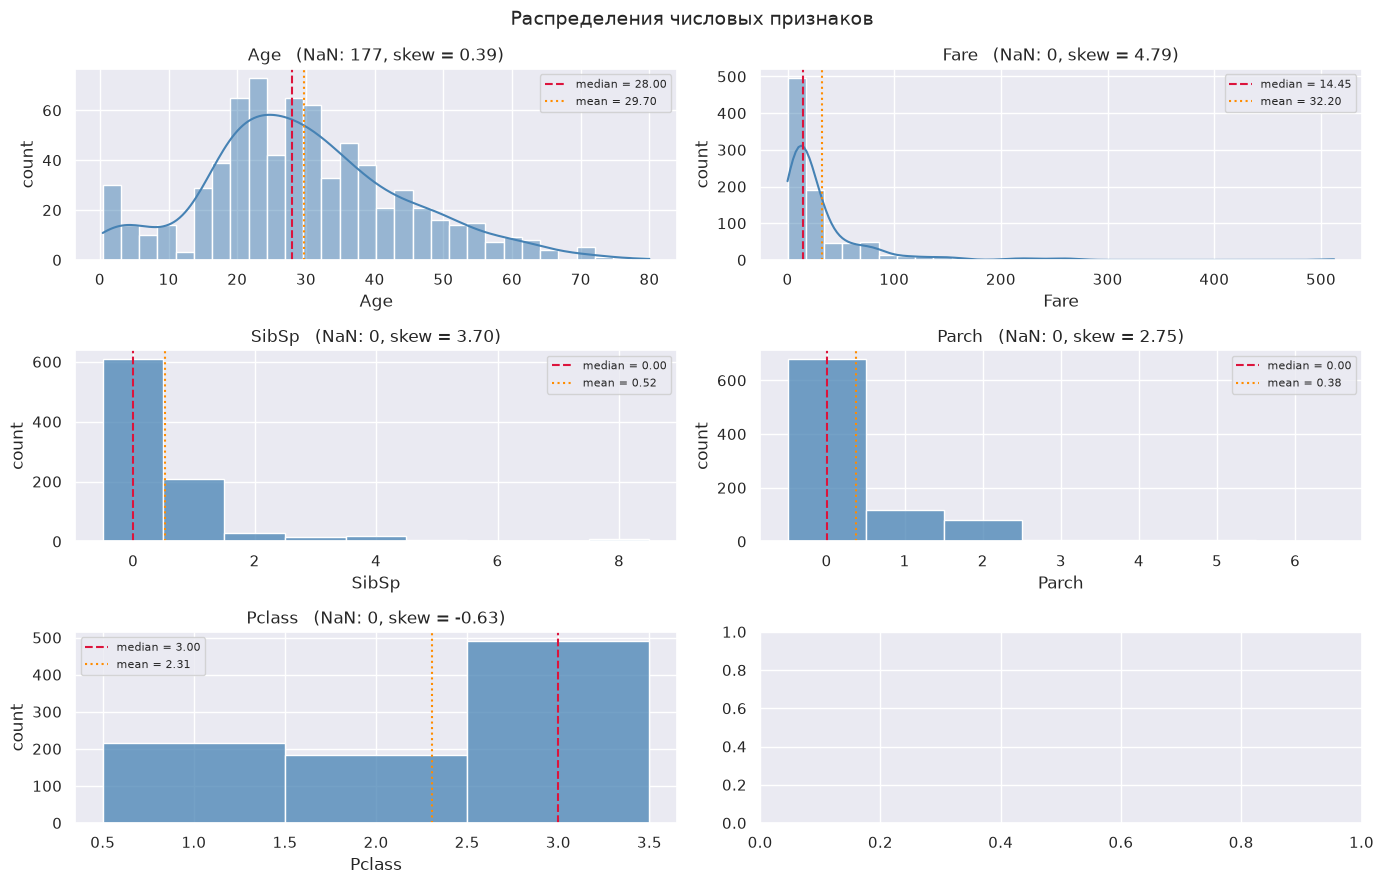

In [23]:
NUM_FEATURES = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']

fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    s = data[col].dropna()
    discrete = s.nunique() <= 15

    sns.histplot(
        x=s,
        bins=s.nunique() if discrete else 30,
        discrete=discrete,
        kde=not discrete,
        color='steelblue',
        edgecolor='white',
        ax=ax,
    )
    ax.axvline(s.median(), color='crimson', ls='--', lw=1.5,
               label=f'median = {s.median():.2f}')
    ax.axvline(s.mean(), color='darkorange', ls=':', lw=1.5,
               label=f'mean = {s.mean():.2f}')

    ax.set_title(f'{col}   (NaN: {data[col].isna().sum()}, '
                 f'skew = {s.skew():.2f})')
    ax.set_xlabel(col)
    ax.set_ylabel('count')
    ax.legend(fontsize=8)

fig.suptitle('Распределения числовых признаков', fontsize=14)
fig.tight_layout()
plt.show()


Мы можем увидеть, что признаки `SibSp`, `Parch`, `Fare` сильно скошены вправо.

## Выводы по предварительному анализу
1. Признаки `PassengerId` и `Name` мы исключаем из наборы признаков, так как они приведут к ненужному запоминанию.
2. Невыживших пассажиров сильно больше, чем выживших(61.62% не выжило). Значит на `Accuracy` ориентироваться нельзя.
3. В данных есть пропуски и строковые признаки. Пропуски в числовых признаках можно заменить медианой из-за скошенности некоторых признаков. Пропуски в строковых признаках можно заменить модой. Некоторые строковые признаки можно преобразовать в числовые через `one-hot encoding`.

# Подготовка данных и выборка
Уберем признаки `PassengerId`, `Name`, `Ticket` из выборки. У строкового признака `Cabin` оставим только палубу, она скорее всего влияет на выживаемость. К остальным строковым признакам применим `one-hot` кодирование. Пропуски в числовых признаках будем заполнять медианой, а в строковых модойh кроме `Cabin`, там пустые значения мы будет помечать `Unknown`, так как зачастую значения `Cabin` неизвестны и отсутствие каюты умышленно. 

In [28]:
print(data['Cabin'].fillna("Unknown").value_counts())

Cabin
Unknown        687
G6               4
C23 C25 C27      4
B96 B98          4
F33              3
              ... 
E17              1
A24              1
C50              1
B42              1
C148             1
Name: count, Length: 148, dtype: int64


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder 
from sklearn.base import BaseEstimator, TransformerMixin
X = data.drop(columns=['Survived'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=52, stratify=y)

num_cols = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']
cat_cols = ['Sex', 'Pclass', 'Embarked']


class CabinDeckExtractor(BaseEstimator, TransformerMixin):
    """Replaces the raw Cabin column with its deck letter (first char)."""
    def __init__(self, col='Cabin', missing='Unknown'):
        self.col = col
        self.missing = missing

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        deck = X[self.col].str[0].fillna(self.missing)
        return deck.to_frame(name='Deck')

preprocess = ColumnTransformer([
    ('num', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median"))
        ]
            ), num_cols),
    ('cat', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown='ignore'))
            ]), cat_cols),
    ('Cabin', Pipeline(
       [
          ("get_deck", CabinDeckExtractor()),
          ("onehot", OneHotEncoder(handle_unknown="ignore"))

       ]) , ['Cabin']
    )
])
X_ready = preprocess.fit_transform(X_train)
print(X_train.shape)
print(X_ready.shape)

(712, 11)
(712, 21)
